# Seminar 2 — The supervised learning workflow

**4IZ566 / 4IZ582**

### Learning objectives

1. Distinguish supervised, unsupervised and reinforcement learning and recognise which one a task calls for.
2. Carry a classification task through the CRISP-DM phases with scikit-learn, with all preprocessing inside a leakage-free pipeline.
3. Evaluate a classifier with metrics and a decision threshold matched to the error costs, and separate model selection from performance estimation.
4. Segment unlabelled data with K-Means, choose the number of clusters and interpret the segments.

### Contents

| Section | Topic | CRISP-DM phase |
|---|---|---|
| 1 | Three kinds of machine learning | — |
| 2 | The CRISP-DM process | — |
| 3 | Supervised learning on the Titanic: the question and the data | Business and data understanding |
| 4 | Train/test split, leakage and pipelines | Data preparation |
| 5 | Logistic regression, decision trees, random forests | Modelling |
| 6 | Metrics, thresholds, cross-validation, model selection | Evaluation |
| 7 | Saving and reusing the model | Deployment |
| 8 | Unsupervised learning: customer segmentation with K-Means | the same phases, without a target |
| 9 | Review | — |

**[core]** denotes the principal material; **[extra]** denotes supplementary study.
Seminar 1 covered loading, cleaning and exploring `data/titanic.csv`; this seminar builds models on it.

## 1 [core] Three kinds of machine learning

| Kind | What the data contain | What the algorithm learns | Example |
|---|---|---|---|
| **Supervised learning** (learning *with* a teacher) | Inputs **and** the correct answer (a *label* or *target*) for every example | A function from inputs to the answer, to be applied to new examples | Predict whether a passenger survived from class, sex, age and fare |
| **Unsupervised learning** (learning *without* a teacher) | Inputs only; no correct answer is provided | Structure hidden in the inputs: groups, directions of variation, anomalies | Group passengers into segments that behave similarly, without using survival |
| **Reinforcement learning** | An environment that returns a reward after each action | A decision policy that maximises the long-run reward | Navigate a ship; the policy is adjusted by rewards for safe arrivals and penalties for collisions |

Supervised learning splits further by the type of the target: a **classification** target is a category (survived / did not survive), a **regression** target is a number (fare paid).
Unsupervised learning splits by the kind of structure sought: **clustering** (groups of similar rows), **dimensionality reduction** (fewer columns), **anomaly detection**.

The same observations can serve either kind of learning. The difference is whether a label column exists and is used:

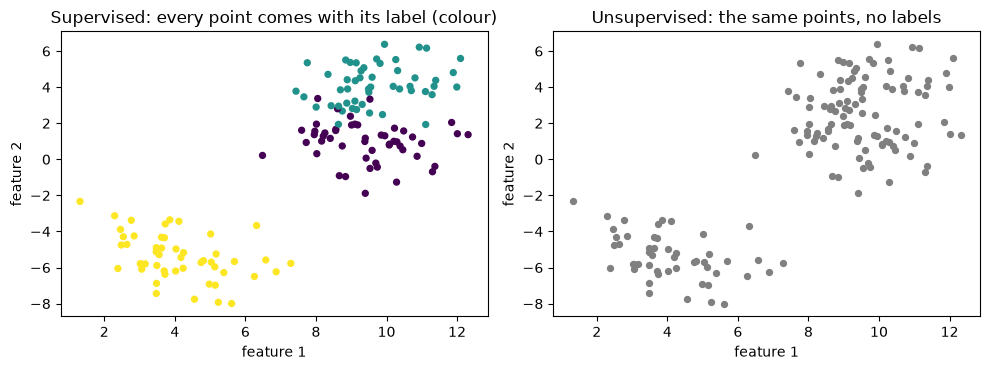

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

X_demo, y_demo = make_blobs(n_samples=150, centers=3, cluster_std=1.2, random_state=4)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].scatter(X_demo[:, 0], X_demo[:, 1], c=y_demo, cmap="viridis", s=18)
axes[0].set_title("Supervised: every point comes with its label (colour)")
axes[1].scatter(X_demo[:, 0], X_demo[:, 1], c="grey", s=18)
axes[1].set_title("Unsupervised: the same points, no labels")
for ax in axes:
    ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")
fig.tight_layout()

- **Left:** a classifier receives the colour of every point and learns a boundary that reproduces the colours on new points. Its quality is measurable: predictions are compared with the known labels.
- **Right:** a clustering algorithm must propose the groups itself. No label exists to compare with, so quality is judged by internal cohesion and by the usefulness of the groups.

Sections 3–7 take the supervised route on the Titanic; section 8 takes the unsupervised route on a customer dataset.

## 2 [core] The CRISP-DM process

CRISP-DM (Cross-Industry Standard Process for Data Mining) is the de-facto standard description of a data-science project.
The phases are iterative: evaluation usually returns the analyst to data preparation or to the business question.

| Phase | Question answered | On the Titanic data |
|---|---|---|
| 1 Business understanding | What decision will the model support? What is a good result worth, what does an error cost? | Predict survival from what is known at boarding; decide which errors matter more. |
| 2 Data understanding | What data exist, what do they contain, how good are they? | 891 passengers, 12 columns, missing ages and cabins, 38 % survived. |
| 3 Data preparation | Which columns, how encoded, how imputed, how split? | Variable roles, train/test split, imputation and encoding *inside a pipeline*. |
| 4 Modelling | Which model families, which hyperparameters? | Logistic regression, decision tree, random forest; grid search. |
| 5 Evaluation | Does the model meet the business goal? Honestly measured? | Confusion matrix, precision/recall, ROC and PR, cost-based threshold, nested cross-validation. |
| 6 Deployment | How does the model reach its users? | Save the pipeline, predict for a new passenger; a web application in seminar 4. |

Two rules apply in all six phases, and the remaining sections apply them:

1. **No quantity may be estimated from the test data** — neither the model parameters, nor the imputation values, the scaling, the feature selection, nor the decision threshold.
2. **The reported performance must be computed on data that played no role in any decision.**

## 3 [core] Supervised learning on the Titanic: the question and the data

### 3.1 Business understanding

- **Task:** for a passenger described by the information available at boarding, predict whether they survived. The target `Survived` is binary, so this is **binary classification**.
- **Admissible inputs:** only what was known *before* the outcome. A column such as "lifeboat number" would be **target leakage** — it is a consequence of surviving, not a predictor.
- **What is a good model?** A model that predicts "did not survive" for every passenger is correct for 62 % of them; 62 % accuracy is therefore the reference level, not a result.
- **Which errors matter?** This depends on the application. Section 6.4 makes the costs explicit; until then both error types count equally.

### 3.2 Data understanding

The loader is the one from seminar 1; the `TITANIC_CSV` environment variable can point to another copy of the file.

In [2]:
import os
from pathlib import Path

csv_path = Path("data") / "titanic.csv"
if not csv_path.exists():
    csv_path = Path(os.environ.get("TITANIC_CSV", csv_path))
titanic = pd.read_csv(csv_path)
print(titanic.shape, "rows x columns")
titanic.head()

(891, 12) rows x columns


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
# missing observations per column
titanic.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [5]:
# class balance of the target: the share of the majority class is the accuracy of a trivial model
titanic["Survived"].value_counts(normalize=True).round(3)

Survived
0    0.616
1    0.384
Name: proportion, dtype: float64

In [6]:
print(titanic.groupby("Sex")["Survived"].mean().round(3))
print(titanic.groupby("Pclass")["Survived"].mean().round(3))

Sex
female    0.742
male      0.189
Name: Survived, dtype: float64
Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64


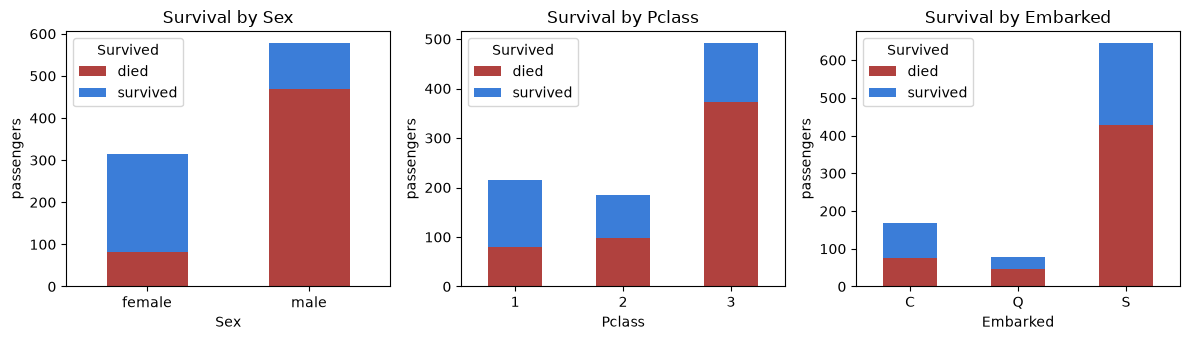

In [7]:
def survival_bars(df, feature, ax):
    counts = pd.crosstab(df[feature], df["Survived"]).rename(columns={0: "died", 1: "survived"})
    counts.plot.bar(stacked=True, ax=ax, color=["#b0413e", "#3b7dd8"], rot=0)
    ax.set_ylabel("passengers"); ax.set_title(f"Survival by {feature}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for feature, ax in zip(["Sex", "Pclass", "Embarked"], axes):
    survival_bars(titanic, feature, ax)
fig.tight_layout()

#### What the data understanding phase tells us

| Finding | Consequence for the next phases |
|---|---|
| `Age` is missing for about 20 % of passengers, `Cabin` for 77 % | Impute `Age`; drop `Cabin` (or keep only a has-cabin flag). |
| `Sex` and `Pclass` separate survivors strongly | A simple model should perform well; `Sex` will appear at the root of a decision tree. |
| 38 % positives | Mild imbalance; accuracy is usable but must be compared with the 62 % baseline. |
| `Name`, `Ticket`, `PassengerId` are identifiers | Not usable as features directly; `Name` contains a title that can be extracted (section 4.6). |

## 4 [core] Data preparation: train/test split, leakage and pipelines

### 4.1 Variable roles

scikit-learn models need **numeric** inputs, **no missing values**, and the features and the target passed **separately** (`X` and `y`).
Before any transformation, assign every column a role.

In [8]:
numeric_variables = ["Age", "SibSp", "Parch", "Fare"]
nominal_variables = ["Sex", "Embarked"]
ordinal_variables = ["Pclass"]                         # 1 < 2 < 3: keep as a number
unwanted_variables = ["PassengerId", "Name", "Ticket", "Cabin"]
target_variable = "Survived"

X = titanic.drop(columns=[target_variable])
y = titanic[target_variable]
print(X.shape, y.shape)

(891, 11) (891,)


### 4.2 Train/test split

The **test set** represents future, unseen passengers. It is split off once, before anything is learned, and used again only in section 6.9.
`stratify=y` keeps the share of survivors equal in both parts; `random_state` makes the split reproducible.

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
print("train:", X_train.shape, " test:", X_test.shape)
print("survival rate  train:", y_train.mean().round(3), " test:", y_test.mean().round(3))

train: (623, 11)  test: (268, 11)
survival rate  train: 0.384  test: 0.384


### 4.3 Column-by-column preprocessing and its limitations

The straightforward way: recode and impute column by column, once for the training part and once for the test part.

In [10]:
manual_train = X_train.copy()
manual_test = X_test.copy()

# recoding: a categorical column into 0/1
manual_train["IsFemale"] = (manual_train["Sex"] == "female").astype(int)
manual_test["IsFemale"] = (manual_test["Sex"] == "female").astype(int)

# imputation: the median is LEARNED from the training data and APPLIED to the test data
impute_value = manual_train["Age"].median()
manual_train["Age"] = manual_train["Age"].fillna(impute_value)
manual_test["Age"] = manual_test["Age"].fillna(impute_value)

print("median age learned on train:", impute_value)
print("missing ages left — train:", manual_train["Age"].isna().sum(), " test:", manual_test["Age"].isna().sum())
manual_train[["Pclass", "IsFemale", "Age"]].head()

median age learned on train: 29.0
missing ages left — train: 0  test: 0


,Pclass,IsFemale,Age
748,1,0,19.0
45,3,0,29.0
28,3,1,29.0
633,1,0,29.0
403,3,0,28.0


This approach works for two columns but does not scale, and three errors are common:

1. computing `impute_value` on the whole dataset (test rows influence a training decision),
2. forgetting to apply the same transformation to the test data,
3. repeating all of it by hand inside every fold of a cross-validation.

A **pipeline** eliminates all three: preprocessing becomes part of the model, is fitted whenever the model is fitted, and is applied whenever the model predicts.

### 4.4 Preprocessing as part of the model

- **`ColumnTransformer`:** applies a different transformation to each group of columns.
- **`Pipeline`:** chains transformations and a final estimator into one object with `fit` and `predict`.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

numeric_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                         ("scale", StandardScaler())])
nominal_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                         ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False))])

preprocess = ColumnTransformer([
    ("num", numeric_pipe, numeric_variables),
    ("nom", nominal_pipe, nominal_variables),
    ("ord", "passthrough", ordinal_variables),
    ("drop", "drop", unwanted_variables),           # dropped by default; being explicit documents the decision
], verbose_feature_names_out=False)

model_lr = Pipeline([("prep", preprocess),
                     ("clf", LogisticRegression(max_iter=1000, random_state=0))])
model_lr

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('nom', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{t

In [12]:
# what the preprocessing produces: fitted on train, applied to train
prepared = preprocess.fit_transform(X_train)
pd.DataFrame(prepared, columns=preprocess.get_feature_names_out()).head()

,Age,SibSp,Parch,Fare,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Pclass
0,-0.831890,0.562957,-0.448665,0.465738,1.0,0.0,0.0,1.0,1.0
1,-0.064873,-0.474682,-0.448665,-0.478269,1.0,0.0,0.0,1.0,3.0
2,-0.064873,-0.474682,-0.448665,-0.481848,0.0,0.0,1.0,0.0,3.0
3,-0.064873,-0.474682,-0.448665,-0.646954,1.0,0.0,0.0,1.0,1.0
4,-0.141574,0.562957,-0.448665,-0.314823,1.0,0.0,0.0,1.0,3.0


In [13]:
# the whole pipeline: one fit, one predict — the test data go in raw
model_lr.fit(X_train, y_train)
print("accuracy on the test set:", round(model_lr.score(X_test, y_test), 3))

accuracy on the test set: 0.799


`drop="if_binary"` encodes a two-category column as one 0/1 column (`Sex_male`) instead of two redundant ones; `Embarked` keeps all three.
`handle_unknown="ignore"` decides what happens when prediction meets a category that was absent during fitting (a port of embarkation that never occurred in the training data): the row is encoded as all zeros instead of raising an error.
Choose the strategy deliberately: an error interrupts prediction visibly, whereas an all-zero row passes silently. Monitor the frequency of unknown categories in production.

### 4.5 Information leakage

**Information leakage** occurs when model development uses information that would not be available under the intended prediction conditions — most often, when something is learned from the validation or test rows.
With the pipeline, every learned step (imputer, scaler, encoder, feature selector) is refitted inside each fold on the training part only. Without it, the scaler below sees all rows before the split.

In [14]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# WRONG — preprocessing fitted on all training rows, then cross-validated as if it were raw data
X_leaky = preprocess.fit_transform(X_train)
leaky = cross_val_score(LogisticRegression(max_iter=1000, random_state=0), X_leaky, y_train,
                        cv=cv, scoring="roc_auc").mean()

# RIGHT — the pipeline is refitted inside every fold
honest = cross_val_score(model_lr, X_train, y_train, cv=cv, scoring="roc_auc").mean()

print(f"leaky  AUC = {leaky:.4f}")
print(f"honest AUC = {honest:.4f}")

leaky  AUC = 0.8508
honest AUC = 0.8508


For imputation and scaling the difference is tiny, which is why the error often goes unnoticed. The following extreme example shows how large it can become: **feature selection** outside the pipeline on data that contain **no signal at all**.

| Component | Experimental design |
|---|---|
| Data | 100 observations, 1,000 random features, random labels (coin flips) |
| Leaking procedure | Select the 10 features most correlated with the label using *all* rows, then cross-validate |
| Valid procedure | Put the selection inside the pipeline so that it sees only the training fold |

In [15]:
from sklearn.feature_selection import SelectKBest, f_classif

rng_noise = np.random.default_rng(4)
Xn = rng_noise.standard_normal((100, 1000))
yn = rng_noise.integers(0, 2, 100)                         # coin flips, unrelated to Xn

selected = SelectKBest(f_classif, k=10).fit_transform(Xn, yn)          # WRONG: sees every label
leaky_noise = cross_val_score(LogisticRegression(max_iter=1000), selected, yn,
                              cv=cv, scoring="roc_auc").mean()

honest_pipe = Pipeline([("select", SelectKBest(f_classif, k=10)),
                        ("clf", LogisticRegression(max_iter=1000))])   # RIGHT: selection per fold
honest_noise = cross_val_score(honest_pipe, Xn, yn, cv=cv, scoring="roc_auc").mean()

print(f"pure noise, selection outside CV : AUC = {leaky_noise:.3f}")
print(f"pure noise, selection inside CV  : AUC = {honest_noise:.3f}   (chance = 0.5)")

pure noise, selection outside CV : AUC = 0.880
pure noise, selection inside CV  : AUC = 0.500   (chance = 0.5)


Rerunning with another seed of `rng_noise` moves the valid estimate by about ±0.1 around 0.5 (a sample of 100 is small), whereas the leaking estimate stays near 0.9. A reported AUC of 0.9 on 100 samples and 1,000 features should prompt the question where the features were selected.

#### [extra] Forms of leakage

| Form | Example | Prevention |
|---|---|---|
| Target leakage | A feature recorded after the outcome (lifeboat number, refund flag) | Check availability at prediction time. |
| Entity leakage | The same customer in training and validation | Group-aware splitting, `GroupKFold`. |
| Temporal leakage | Future rows inform predictions for earlier periods | Split consistent with the prediction horizon. |
| Preprocessing leakage | Imputation, scaling, selection or resampling before the split | Fit inside the pipeline. |
| Test-set leakage | Changing the model after looking at test performance | Use the test set once, at the end. |

### 4.6 [extra] Feature engineering inside the pipeline

New columns derived from existing ones also belong in the pipeline, so that they are computed automatically at deployment (section 7).
`FunctionTransformer` wraps a plain function; the `ColumnTransformer` then sees the new columns.

In [16]:
from sklearn.preprocessing import FunctionTransformer

def add_features(df):
    out = df.copy()
    title = out["Name"].str.extract(r",\s*([^.]+)\.")[0].str.strip()
    out["Title"] = title.where(title.isin(["Mr", "Mrs", "Miss", "Master"]), "Other")
    out["FamilySize"] = out["SibSp"] + out["Parch"] + 1
    return out

preprocess_fe = ColumnTransformer([
    ("num", numeric_pipe, numeric_variables + ["FamilySize"]),
    ("nom", nominal_pipe, nominal_variables + ["Title"]),
    ("ord", "passthrough", ordinal_variables),
], remainder="drop", verbose_feature_names_out=False)

model_fe = Pipeline([("features", FunctionTransformer(add_features)),
                     ("prep", preprocess_fe),
                     ("clf", LogisticRegression(max_iter=1000, random_state=0))])

for name, m in (("baseline features", model_lr), ("+ Title, FamilySize", model_fe)):
    print(f"{name:22s} CV accuracy = {cross_val_score(m, X_train, y_train, cv=cv).mean():.3f}")

baseline features      CV accuracy = 0.795
+ Title, FamilySize    CV accuracy = 0.823


## 5 [core] Modelling

Three model families, all on the same preprocessing. Each is fitted on the training part only; the test set is not used until section 6.9.

### 5.1 Logistic regression

- A linear model for a binary target: it learns one weight per feature and an intercept.
- The weighted sum is the **log-odds** (logit) of the positive class; the sigmoid turns it into a probability.
- scikit-learn's implementation needs numeric, complete, preferably scaled inputs — which the pipeline provides.

In [17]:
model_lr.fit(X_train, y_train)
clf = model_lr.named_steps["clf"]

coefficients = pd.DataFrame({
    "feature": model_lr.named_steps["prep"].get_feature_names_out(),
    "weight (log-odds)": clf.coef_[0].round(3),
    "odds ratio": np.exp(clf.coef_[0]).round(3),
}).sort_values("odds ratio", ascending=False)
print("intercept:", clf.intercept_[0].round(3))
coefficients

intercept: 3.697


,feature,weight (log-odds),odds ratio
6,Embarked_Q,0.295,1.342
3,Fare,0.120,1.128
5,Embarked_C,0.006,1.006
2,Parch,-0.043,0.958
1,SibSp,-0.290,0.748
7,Embarked_S,-0.300,0.741
0,Age,-0.547,0.579
8,Pclass,-1.073,0.342
4,Sex_male,-2.548,0.078


#### Interpreting the weights

- A weight is the change in the **log-odds** of surviving for a one-unit increase in the feature, holding the others fixed.
- `exp(weight)` is the **odds ratio**: how a one-unit increase multiplies the odds `P(survived) / P(died)`. An odds ratio of 1 means no effect.
- Numeric features were standardised, so "one unit" is one standard deviation; for `Pclass` it is one class step; for a one-hot column it is the difference from the baseline category.
- Reading the table: `Sex_male` has an odds ratio far below 1 — a man has a small fraction of the odds of survival of an otherwise identical woman; each step down in class divides the odds by about three; age reduces them mildly.

#### Exercise

What is the probability of survival of a 47-year-old woman travelling alone in the third class, who paid 8 pounds and embarked in Southampton?

1. Build a one-row `DataFrame` with the same columns as `X` and obtain the probability with `predict_proba`.
2. Reproduce the number manually: transform the row with the preprocessing part of the pipeline (`model_lr[:-1]`), take the dot product with `clf.coef_`, add the intercept, convert log-odds → odds → probability.

In [18]:
passenger = pd.DataFrame([{
    "PassengerId": 0, "Pclass": 3, "Name": "Doe, Mrs. Jane", "Sex": "female", "Age": 47.0,
    "SibSp": 0, "Parch": 0, "Ticket": "n/a", "Fare": 8.0, "Cabin": None, "Embarked": "S",
}])

# your code

#### Solution

In [19]:
print("predict_proba  :", model_lr.predict_proba(passenger)[0].round(4), "  (died, survived)")

row = model_lr[:-1].transform(passenger)              # everything except the classifier
log_odds = row @ clf.coef_.T + clf.intercept_
odds = np.exp(log_odds)
probability = odds / (1 + odds)
print("log-odds       :", log_odds.round(4).item())
print("odds           :", odds.round(4).item())
print("P(survived)    :", probability.round(4).item())

predict_proba  : [0.6088 0.3912]   (died, survived)
log-odds       : -0.4423
odds           : 0.6426
P(survived)    : 0.3912


### 5.2 Decision tree

A tree asks one question per node (`Sex_male <= 0.5?`) and sends the passenger left or right until a leaf, which votes by majority.
Trees need no scaling and are readable as long as they remain small.

In [20]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

model_tree = Pipeline([("prep", preprocess),
                       ("clf", DecisionTreeClassifier(max_depth=3, random_state=0))])
model_tree.fit(X_train, y_train)

feature_names = list(model_tree.named_steps["prep"].get_feature_names_out())
print(export_text(model_tree.named_steps["clf"], feature_names=feature_names))

|--- Sex_male <= 0.50
|   |--- Pclass <= 2.50
|   |   |--- Fare <= -0.04
|   |   |   |--- class: 1
|   |   |--- Fare >  -0.04
|   |   |   |--- class: 1
|   |--- Pclass >  2.50
|   |   |--- Fare <= -0.48
|   |   |   |--- class: 1
|   |   |--- Fare >  -0.48
|   |   |   |--- class: 0
|--- Sex_male >  0.50
|   |--- Age <= -2.02
|   |   |--- SibSp <= 2.64
|   |   |   |--- class: 1
|   |   |--- SibSp >  2.64
|   |   |   |--- class: 0
|   |--- Age >  -2.02
|   |   |--- Pclass <= 1.50
|   |   |   |--- class: 0
|   |   |--- Pclass >  1.50
|   |   |   |--- class: 0



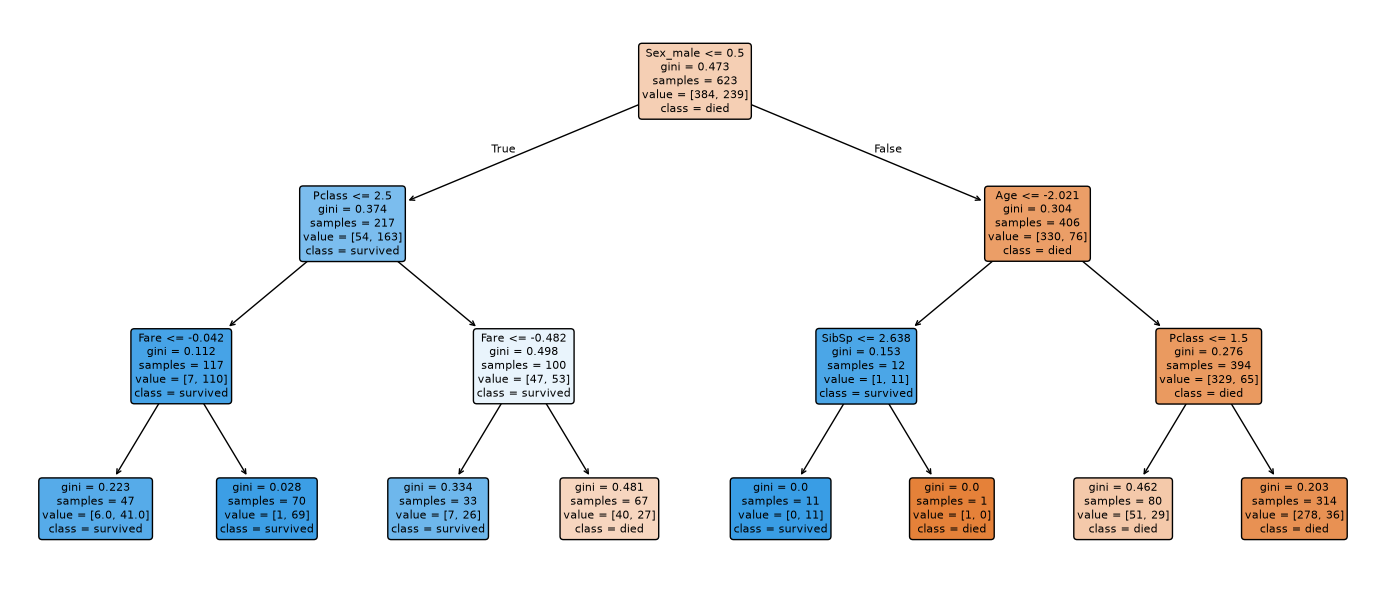

In [21]:
fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(model_tree.named_steps["clf"], feature_names=feature_names,
          class_names=["died", "survived"], filled=True, rounded=True, fontsize=8, ax=ax)
fig.tight_layout()

#### Overfitting: an unlimited tree memorises the training data

Training accuracy measures how well the model reproduces the examples it saw. Only held-out data can tell whether the extra complexity learned anything general.
(The held-out figures below are cross-validated on the training part — the test set is still untouched.)

In [22]:
for depth in (1, 3, 6, None):
    tree = Pipeline([("prep", preprocess), ("clf", DecisionTreeClassifier(max_depth=depth, random_state=0))])
    train_acc = tree.fit(X_train, y_train).score(X_train, y_train)
    cv_acc = cross_val_score(tree, X_train, y_train, cv=cv).mean()
    print(f"max_depth={str(depth):>4}:  training accuracy {train_acc:.3f}   cross-validated accuracy {cv_acc:.3f}   "
          f"leaves {tree.named_steps['clf'].get_n_leaves()}")

max_depth=   1:  training accuracy 0.791   cross-validated accuracy 0.791   leaves 2
max_depth=   3:  training accuracy 0.830   cross-validated accuracy 0.812   leaves 8
max_depth=   6:  training accuracy 0.883   cross-validated accuracy 0.814   leaves 33
max_depth=None:  training accuracy 0.976   cross-validated accuracy 0.788   leaves 145


### 5.3 Random forest

Many trees, each grown on a bootstrap sample of the rows and a random subset of the features at every split; the forest votes.
It is less prone to overfitting than a single tree and provides a **feature importance** — how much each feature reduced impurity across all trees.

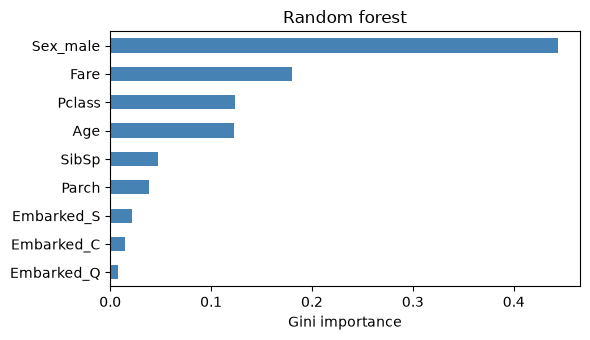

In [23]:
from sklearn.ensemble import RandomForestClassifier

model_rf = Pipeline([("prep", preprocess),
                     ("clf", RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42))])
model_rf.fit(X_train, y_train)

importances = pd.Series(model_rf.named_steps["clf"].feature_importances_, index=feature_names).sort_values()
fig, ax = plt.subplots(figsize=(6, 3.5))
importances.plot.barh(ax=ax, color="steelblue"); ax.set_xlabel("Gini importance"); ax.set_title("Random forest")
fig.tight_layout()

### 5.4 Comparing the three families

One comparison, same folds, training data only. The numbers are cross-validated estimates, not the final assessment, which follows in section 6.9.

In [24]:
candidates = {"logistic regression": model_lr, "decision tree (depth 3)": model_tree, "random forest": model_rf}
for name, m in candidates.items():
    scores = cross_val_score(m, X_train, y_train, cv=cv)
    print(f"{name:26s} accuracy {scores.mean():.3f} ± {scores.std():.3f}")

logistic regression        accuracy 0.795 ± 0.018
decision tree (depth 3)    accuracy 0.812 ± 0.026
random forest              accuracy 0.835 ± 0.031


## 6 [core] Evaluation

### 6.1 Baseline and accuracy

Every reported score needs a reference point. `DummyClassifier` always predicts the majority class.

In [25]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("baseline accuracy (always 'died') :", round(baseline.score(X_test, y_test), 3))
print("logistic regression accuracy      :", round(model_lr.score(X_test, y_test), 3))

baseline accuracy (always 'died') : 0.616
logistic regression accuracy      : 0.799


### 6.2 Confusion matrix, precision and recall

Evaluation means comparing predictions with the truth; the confusion matrix is the complete comparison, every other metric is a summary of it.

| | predicted died | predicted survived |
|---|---|---|
| **actually died** | true negative (TN) | false positive (FP) |
| **actually survived** | false negative (FN) | true positive (TP) |

- **Precision** = TP / (TP + FP): of those predicted to survive, how many did.
- **Recall** (sensitivity) = TP / (TP + FN): of those who survived, how many were found.
- **F1** = harmonic mean of the two.

[[140  25]
 [ 29  74]]
              precision    recall  f1-score   support

        died      0.828     0.848     0.838       165
    survived      0.747     0.718     0.733       103

    accuracy                          0.799       268
   macro avg      0.788     0.783     0.785       268
weighted avg      0.797     0.799     0.798       268



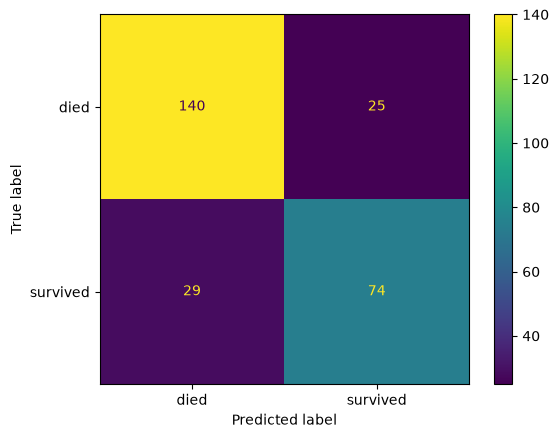

In [26]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

y_pred = model_lr.predict(X_test)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=["died", "survived"], digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["died", "survived"]);

### 6.3 Scores instead of decisions: ROC and precision–recall curves

| Output | Interpretation |
|---|---|
| `predict_proba` | Estimated class probabilities; calibration should be assessed. |
| `decision_function` | A score, not necessarily a probability. |
| `predict` | `predict_proba >= 0.5` for binary classifiers — a default decision rule, not a deliberate choice. |

Curves evaluate the **ranking** a model produces, for every possible threshold at once.

- **ROC curve:** true-positive rate against false-positive rate; the area (AUC) is 0.5 for random ranking, 1 for perfect.
- **Precision–recall curve:** precision against recall; the area-like summary is **average precision (AP)**; random ranking gives AP = prevalence.
- **Under strong class imbalance** (for example 3 % positives) the ROC curve appears favourable for almost any model, because the false-positive *rate* is diluted by the large negative class. Precision is not diluted: when the question is how many of the flagged cases are real, the precision–recall curve is the relevant one.

ROC AUC           : 0.8497   (random = 0.5)
Average precision : 0.8039   (random = prevalence = 0.384)


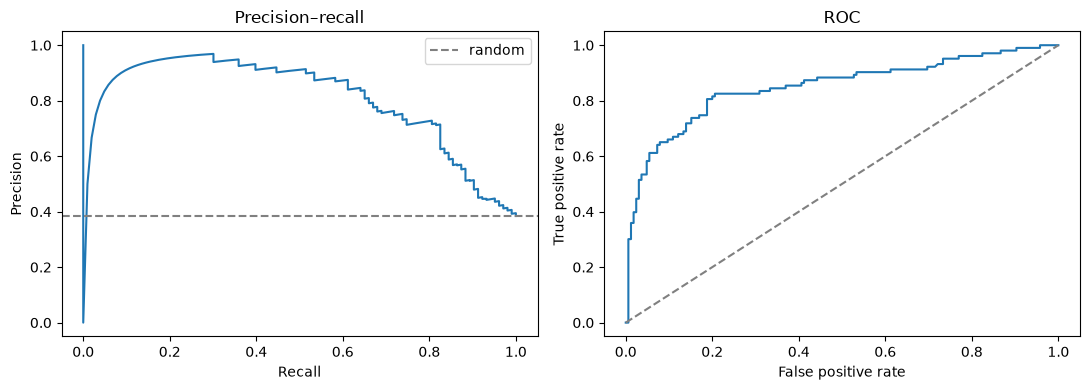

In [27]:
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, roc_curve

proba_te = model_lr.predict_proba(X_test)[:, 1]
prevalence = y_test.mean()
print("ROC AUC           :", round(roc_auc_score(y_test, proba_te), 4), "  (random = 0.5)")
print("Average precision :", round(average_precision_score(y_test, proba_te), 4),
      f"  (random = prevalence = {prevalence:.3f})")

prec, rec, _ = precision_recall_curve(y_test, proba_te)
fpr, tpr, _ = roc_curve(y_test, proba_te)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(rec, prec); axes[0].axhline(prevalence, ls="--", c="grey", label="random")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision"); axes[0].set_title("Precision–recall"); axes[0].legend()
axes[1].plot(fpr, tpr); axes[1].plot([0, 1], [0, 1], ls="--", c="grey")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate"); axes[1].set_title("ROC")
fig.tight_layout()

### 6.4 Choosing the decision threshold from error costs

This step returns to business understanding: the two errors rarely cost the same. Suppose a **false negative costs ten times a false positive** (a missed fraud case or a missed diagnosis).

1. Obtain **out-of-fold** predictions for the training data with `cross_val_predict` — every training row is scored by a model that did not see it.
2. Evaluate the candidate thresholds by total cost. Candidates: the distinct predicted scores plus the two extremes; an evenly spaced grid may miss the minimum.
3. Select the threshold with the lowest total cost.
4. Evaluate the selected procedure on the test set, once.

The threshold is a learned part of the decision procedure. Choosing it on the test labels is test-set leakage.

In [28]:
from sklearn.model_selection import cross_val_predict

def expected_cost(y_true, proba, threshold, cost_fp, cost_fn):
    pred = (proba >= threshold).astype(int)
    fp = int(((pred == 1) & (y_true == 0)).sum())
    fn = int(((pred == 0) & (y_true == 1)).sum())
    return cost_fp * fp + cost_fn * fn

def best_threshold(y_true, proba, cost_fp, cost_fn):
    candidates = sorted(set(np.asarray(proba).tolist()) | {0.0, float(np.max(proba)) + 1e-9})
    return min(candidates, key=lambda t_: (expected_cost(y_true, proba, t_, cost_fp, cost_fn), t_))

COST_FP, COST_FN = 1.0, 10.0
y_tr = y_train.to_numpy(); y_te = y_test.to_numpy()

oof = cross_val_predict(model_lr, X_train, y_train, cv=cv, method="predict_proba")[:, 1]   # 1) out-of-fold scores
t_star = best_threshold(y_tr, oof, COST_FP, COST_FN)                                         # 2–3) cheapest threshold
print(f"threshold chosen on out-of-fold training scores: {t_star:.3f}")
print(f"test cost at 0.50   : {expected_cost(y_te, proba_te, 0.5, COST_FP, COST_FN)}")          # 4) test set, once
print(f"test cost at {t_star:.3f}  : {expected_cost(y_te, proba_te, t_star, COST_FP, COST_FN)}")

threshold chosen on out-of-fold training scores: 0.084
test cost at 0.50   : 315.0
test cost at 0.084  : 163.0


threshold tuned on the test set: 0.052, cost 158.0  <- optimistic by construction


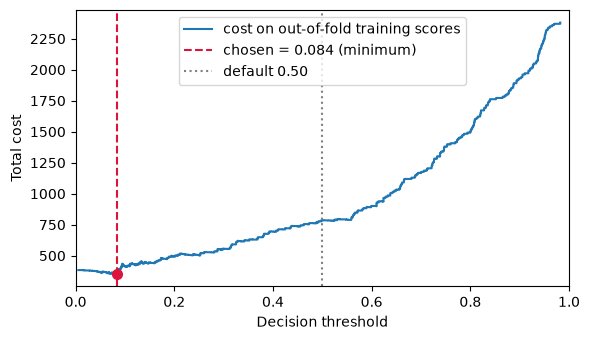

In [29]:
# What NOT to do — choose the threshold on the test labels and report the cost on the same labels.
t_cheat = best_threshold(y_te, proba_te, COST_FP, COST_FN)
print(f"threshold tuned on the test set: {t_cheat:.3f}, cost {expected_cost(y_te, proba_te, t_cheat, COST_FP, COST_FN)}"
      "  <- optimistic by construction")

# Cost curve over the candidate thresholds (every distinct out-of-fold score), not over an even grid.
cands = np.sort(np.unique(oof))
costs = np.array([expected_cost(y_tr, oof, c, COST_FP, COST_FN) for c in cands])
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.step(cands, costs, where="post", label="cost on out-of-fold training scores")
ax.plot(t_star, costs[cands == t_star][0], "o", c="crimson", ms=7, zorder=3)
ax.axvline(t_star, c="crimson", ls="--", label=f"chosen = {t_star:.3f} (minimum)")
ax.axvline(0.5, c="grey", ls=":", label="default 0.50")
ax.set_xlim(0, 1); ax.set_xlabel("Decision threshold"); ax.set_ylabel("Total cost"); ax.legend()
fig.tight_layout()

When false negatives are expensive the chosen threshold drops below 0.5: the classifier predicts the positive class more readily. The cost curve is flat around its minimum, so neighbouring thresholds perform almost equally; the choice is robust to small shifts, and the test cost confirms the gain over the default.
[extra] With calibrated probabilities the cost-optimal threshold is `cost_fp / (cost_fp + cost_fn)` in closed form; calibration curves, Brier score and `CalibratedClassifierCV` are the tools to check whether the predicted probabilities are calibrated.

### 6.5 Cross-validation

One train/test split gives one number, and the more rows the test set takes, the less the model has to learn from.
**k-fold cross-validation** divides the available rows into k parts; each part serves once as the held-out fold while the model is trained on the other k − 1. The k scores are averaged.

| Instance | fold 1 | fold 2 | fold 3 |
|:---:|:---:|:---:|:---:|
| D1 | holdout | train | train |
| D2 | train | holdout | train |
| D3 | train | train | holdout |

- **Stratified** folds keep the class ratio in every fold — better in bias and variance than plain folds (Kohavi, 1995).
- Typical k: 5 or 10. The spread of the k scores shows how much a single split could have misled.
- It estimates the quality of the **procedure**, not of one fitted model; the final model is refitted on all training rows.

In [30]:
scores = cross_val_score(model_lr, X_train, y_train, cv=cv, scoring="accuracy")
print("accuracy per fold:", scores.round(3))
print("mean:", scores.mean().round(3), " std:", scores.std().round(3))

accuracy per fold: [0.8   0.784 0.768 0.823 0.798]
mean: 0.795  std: 0.018


### 6.6 Hyperparameter tuning with `GridSearchCV`

Hyperparameters are the settings a model does not learn itself: tree depth, minimum leaf size, the regularisation strength `C` of logistic regression.
`GridSearchCV` tries every combination in a grid, cross-validates each, and refits the best one on all the data it was given.
Parameters of a pipeline step are addressed as `step__parameter`.

In [31]:
from sklearn.model_selection import GridSearchCV

param_grid = {"clf__max_depth": [2, 3, 4, 5, 6, 8],
              "clf__min_samples_leaf": [1, 5, 10, 20]}
tree_pipe = Pipeline([("prep", preprocess), ("clf", DecisionTreeClassifier(random_state=0))])

inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=1)
search = GridSearchCV(tree_pipe, param_grid, scoring="accuracy", cv=inner)
search.fit(X_train, y_train)

print("best parameters :", search.best_params_)
print("best_score_     :", round(search.best_score_, 4), "  <- the score that won the comparison")

best parameters : {'clf__max_depth': 3, 'clf__min_samples_leaf': 5}
best_score_     : 0.817   <- the score that won the comparison


### 6.7 Model selection is not performance estimation

`best_score_` was used to *choose* the winner among 24 configurations. The winner of a comparison always looks better than it will on fresh data — the same folds served both to pick it and to score it (**selection optimism**).

**Nested cross-validation** separates the two tasks:

| Loop | Purpose |
|---|---|
| Inner (`GridSearchCV`) | Select hyperparameters. |
| Outer (`cross_val_score` around the search) | Evaluate the whole selection procedure on rows the inner search never saw. |

In [32]:
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
nested = cross_val_score(search, X_train, y_train, cv=outer, scoring="accuracy")
print("nested estimate :", nested.mean().round(4), "  per fold:", nested.round(3))
print("best_score_     :", round(search.best_score_, 4), "  (optimistic by", round(search.best_score_ - nested.mean(), 4), ")")

nested estimate : 0.8106   per fold: [0.848 0.808 0.792 0.815 0.79 ]
best_score_     : 0.817   (optimistic by 0.0065 )


#### Reporting results

- Report the outer-fold scores and their mean as the estimate of the selection procedure; the fold-to-fold spread as its uncertainty.
- Report `best_params_` of the search refitted on all training data separately; that is the model that is deployed.
- The standard deviation across folds is not a confidence interval.

### 6.8 [extra] Automated model search

`RandomizedSearchCV` samples configurations from distributions instead of enumerating a grid, and the `clf` step itself can be a search dimension — three model families in one search. AutoML libraries (`FLAML`, `TPOT`, `auto-sklearn`) add budget management, early stopping and ensembling on top of the same idea.

In [33]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import HistGradientBoostingClassifier
from scipy.stats import loguniform, randint

space = [
    {"clf": [LogisticRegression(max_iter=2000, random_state=0)], "clf__C": loguniform(1e-3, 1e2)},
    {"clf": [RandomForestClassifier(random_state=0)],
     "clf__n_estimators": randint(50, 200), "clf__min_samples_leaf": randint(1, 20)},
    {"clf": [HistGradientBoostingClassifier(random_state=0)],
     "clf__learning_rate": loguniform(1e-2, 3e-1), "clf__max_leaf_nodes": randint(8, 64)},
]
automl = RandomizedSearchCV(model_lr, space, n_iter=12, scoring="roc_auc", cv=inner, random_state=0, n_jobs=2)
automl.fit(X_train, y_train)
print("winner:", type(automl.best_estimator_.named_steps["clf"]).__name__,
      {k: (round(float(v), 4) if isinstance(v, float) else v) for k, v in automl.best_params_.items() if k != "clf"})
print("selection score (optimistic):", round(automl.best_score_, 4))

res = pd.DataFrame(automl.cv_results_)
res["family"] = res["param_clf"].map(lambda e: type(e).__name__)
res.groupby("family")["mean_test_score"].agg(["count", "max", "mean"]).round(4)

winner: HistGradientBoostingClassifier {'clf__learning_rate': 0.069, 'clf__max_leaf_nodes': 45}
selection score (optimistic): 0.8606


,count,max,mean
family,,,
HistGradientBoostingClassifier,3,0.8606,0.8564
LogisticRegression,4,0.8526,0.8523
RandomForestClassifier,5,0.8604,0.8575


In [34]:
try:
    from flaml import AutoML
    # FLAML gets the already-prepared matrix: its internal validation therefore sees an imputer and scaler
    # fitted on all training rows — a small leak, acceptable for a demo, not for a report.
    Xp_train = preprocess.fit_transform(X_train)
    automl2 = AutoML()
    automl2.fit(Xp_train, y_train, task="classification", metric="roc_auc", time_budget=20, verbose=0, n_jobs=2)
    print("FLAML best:", automl2.best_estimator)
except ImportError:
    print("FLAML is not installed here — the hand-written search above makes the same point.")

FLAML is not installed here — the hand-written search above makes the same point.


Decisions outside the search procedure: the task definition, which features are admissible, the metric, the decision threshold, and whether the expected benefit justifies the computing cost.

### 6.9 Which model performed best?

The test set, used once, for every candidate — including the tuned ones. This is the number that goes into the report.

In [35]:
final = {
    "baseline (majority class)": baseline,
    "logistic regression": model_lr,
    "decision tree, depth 3": model_tree,
    "decision tree, tuned": search,
    "random forest": model_rf,
    "randomised search winner": automl,
}
results = pd.DataFrame({
    "test accuracy": {k: m.score(X_test, y_test) for k, m in final.items()},
    "test ROC AUC": {k: roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]) for k, m in final.items()},
}).round(3)
results

,test accuracy,test ROC AUC
baseline (majority class),0.616,0.500
logistic regression,0.799,0.850
"decision tree, depth 3",0.795,0.830
"decision tree, tuned",0.787,0.830
random forest,0.817,0.862
randomised search winner,0.839,0.839


The ranking of close scores on 268 test passengers is not stable — a different split could reorder them.
That is why model *selection* happened on cross-validated training scores; the test set only confirms that the chosen model generalises.

### 6.10 [extra] Learning curves

How does validation performance change with the amount of training data? A large gap between training and validation scores that narrows with more data points to variance; both low points to bias.

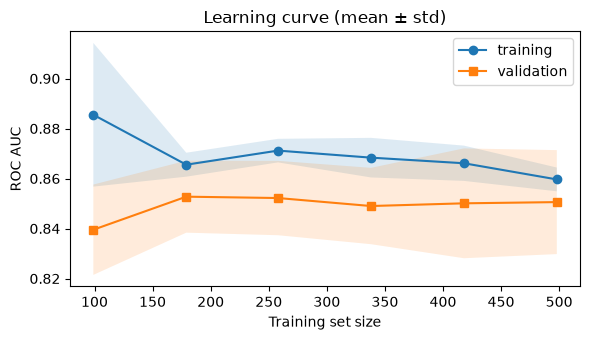

In [36]:
from sklearn.model_selection import learning_curve

sizes, train_sc, val_sc = learning_curve(model_lr, X_train, y_train, cv=cv, scoring="roc_auc",
                                         train_sizes=np.linspace(.2, 1.0, 6), shuffle=True, random_state=0)
fig, ax = plt.subplots(figsize=(6, 3.5))
for arr, lab, mk in ((train_sc, "training", "o-"), (val_sc, "validation", "s-")):
    ax.plot(sizes, arr.mean(1), mk, label=lab)
    ax.fill_between(sizes, arr.mean(1) - arr.std(1), arr.mean(1) + arr.std(1), alpha=.15)
ax.set_xlabel("Training set size"); ax.set_ylabel("ROC AUC"); ax.legend(); ax.set_title("Learning curve (mean ± std)")
fig.tight_layout()

## 7 [core] Deployment: saving and reusing the model

Because the pipeline contains the preprocessing, the deployed object needs nothing but raw passenger records.
`joblib` serialises the fitted pipeline; the loading side must run the same library versions (`requirements-notebooks.txt`).

In [37]:
import joblib

final_model = search.best_estimator_                 # the tuned tree, refitted on all training rows
joblib.dump(final_model, "titanic_model.joblib")

loaded = joblib.load("titanic_model.joblib")       # joblib files execute code on load: open only files you wrote yourself
new_passengers = pd.DataFrame([
    {"PassengerId": 1, "Pclass": 1, "Name": "A, Mrs. B", "Sex": "female", "Age": 35.0, "SibSp": 1, "Parch": 0,
     "Ticket": "x", "Fare": 80.0, "Cabin": "C85", "Embarked": "C"},
    {"PassengerId": 2, "Pclass": 3, "Name": "C, Mr. D", "Sex": "male", "Age": None, "SibSp": 0, "Parch": 0,
     "Ticket": "y", "Fare": 7.9, "Cabin": None, "Embarked": "Q"},
])
print("predicted class      :", loaded.predict(new_passengers))
print("P(survived)          :", loaded.predict_proba(new_passengers)[:, 1].round(3))

predicted class      : [1 0]
P(survived)          : [0.986 0.115]


- The second passenger has no age; the imputer inside the pipeline handles it exactly as during training.
- A decision threshold other than 0.5 (section 6.4) is applied by the caller: `proba >= t_star`.
- Seminar 4 wraps a model like this in a web application; in production add monitoring of input distributions and of unknown categories.

## 8 [core] Unsupervised learning: customer segmentation with K-Means

The same CRISP-DM phases, but the data have **no target column**. The algorithm proposes groups; the analyst decides whether they are meaningful.

### 8.1 Business and data understanding

A shopping mall has 200 customers with age, annual income and a *spending score* (1–100) assigned by the mall from purchase behaviour.
Marketing wants a small number of **segments** to address differently. No reference segmentation exists; this is what makes the task unsupervised.

In [38]:
csv_path = Path("data") / "customers.csv"
if not csv_path.exists():
    csv_path = Path(os.environ.get("CUSTOMERS_CSV", csv_path))
customers = pd.read_csv(csv_path)
print(customers.shape)
customers.head()

(200, 5)


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [39]:
customers.describe().round(1)

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.0,200.0,200.0,200.0
mean,100.5,38.8,60.6,50.2
std,57.9,14.0,26.3,25.8
min,1.0,18.0,15.0,1.0
25%,50.8,28.8,41.5,34.8
50%,100.5,36.0,61.5,50.0
75%,150.2,49.0,78.0,73.0
max,200.0,70.0,137.0,99.0


### 8.2 Data preparation

K-Means measures **Euclidean distance** between rows. Two consequences:

1. Every feature must be numeric and on a comparable scale; otherwise the feature with the largest units determines the clusters alone.
2. A 0/1 column such as gender is numeric, but in Euclidean distance it separates the rows into two groups that no other feature can bridge: every cluster splits into a male and a female part. Gender is therefore kept for *describing* the segments, and the clustering uses the three numeric columns.

In [40]:
segments = customers.rename(columns={"Genre": "gender", "Age": "age",
                                     "Annual Income (k$)": "income", "Spending Score (1-100)": "spending_score"})
segments["is_male"] = (segments["gender"] == "Male").astype(int)
features = ["age", "income", "spending_score"]

scaler = StandardScaler()
Z = scaler.fit_transform(segments[features])            # unsupervised: no split, fit on everything
pd.DataFrame(Z, columns=features).describe().round(2).loc[["mean", "std"]]

,age,income,spending_score
mean,-0.0,-0.0,-0.0
std,1.0,1.0,1.0


#### The extreme example: income in dollars instead of thousands

Same data, same algorithm, one column multiplied by 1,000. The clusters become vertical bands determined by income alone, with spending ignored, and the silhouette score is even higher.

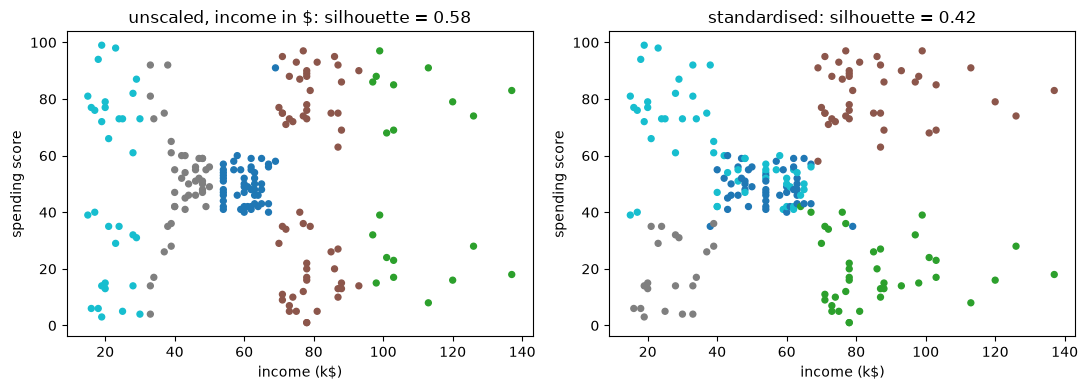

In [41]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

dollars = segments[features].assign(income=segments["income"] * 1000)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (label, data) in zip(axes, (("unscaled, income in $", dollars.to_numpy()), ("standardised", Z))):
    labels = KMeans(n_clusters=5, n_init=10, random_state=0).fit_predict(data)
    ax.scatter(segments["income"], segments["spending_score"], c=labels, cmap="tab10", s=18)
    ax.set_title(f"{label}: silhouette = {silhouette_score(data, labels):.2f}")
    ax.set_xlabel("income (k$)"); ax.set_ylabel("spending score")
fig.tight_layout()

### 8.3 K-Means

K-Means picks k centres, assigns every row to the nearest centre, moves each centre to the mean of its rows, and repeats until nothing changes.
The result depends on the starting centres, so `n_init=10` runs it ten times and keeps the best (lowest **inertia**, the sum of squared distances to the centres).

In [42]:
km = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Z)
print("iterations:", km.n_iter_, " inertia:", round(km.inertia_, 1))
print("cluster sizes:", np.bincount(km.labels_))
# centres back in the original units, so that they can be read
pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=features).round(1)

iterations: 7  inertia: 168.2
cluster sizes: [47 39 40 20 54]


,age,income,spending_score
0,55.6,54.4,48.9
1,39.9,86.1,19.4
2,32.9,86.1,81.5
3,46.2,26.8,18.3
4,25.2,41.1,62.2


### 8.4 How many clusters?

There is no label to score against, so k is chosen from **internal** criteria:

- **Elbow:** inertia always drops with k; look for the k after which it drops much more slowly.
- **Silhouette:** for each row, how much closer it is to its own cluster than to the nearest other one (−1 … 1); average over rows, pick the k with the highest value.

Both are heuristics. The final test is whether the segments are distinct enough for marketing to act on.

highest silhouette at k = 6


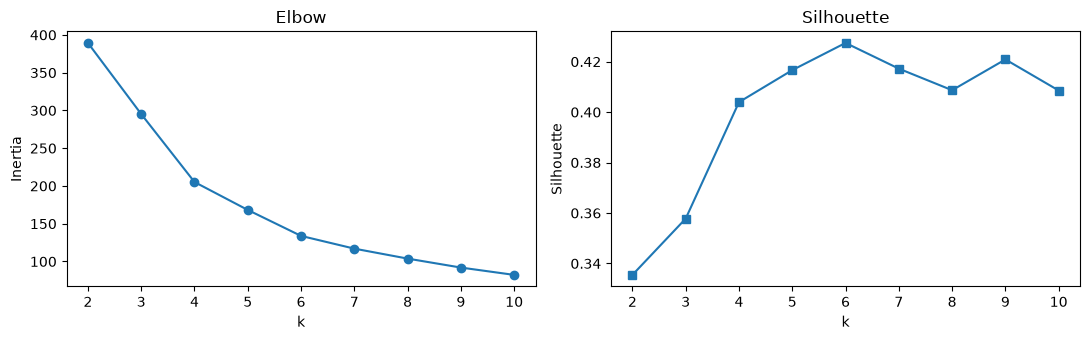

In [43]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    model_k = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z)
    inertia.append(model_k.inertia_); sil.append(silhouette_score(Z, model_k.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(list(ks), inertia, "o-"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia"); axes[0].set_title("Elbow")
axes[1].plot(list(ks), sil, "s-"); axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette"); axes[1].set_title("Silhouette")
fig.tight_layout()
best_k = list(ks)[int(np.argmax(sil))]
print("highest silhouette at k =", best_k)

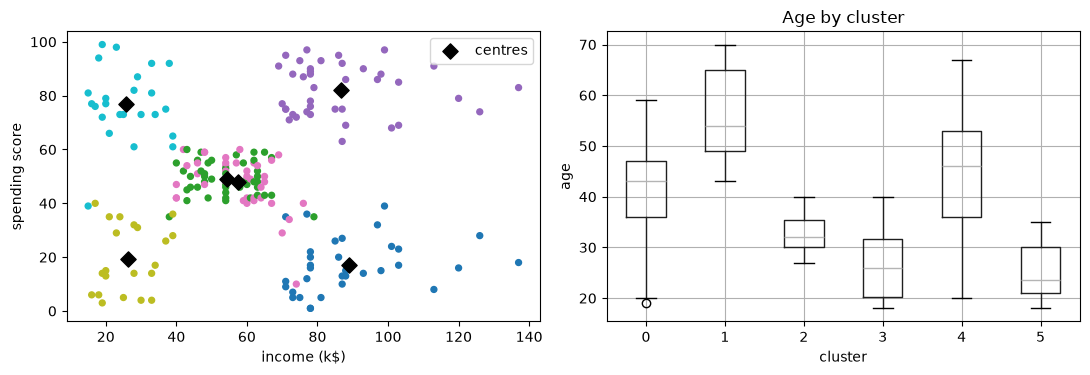

In [44]:
km = KMeans(n_clusters=best_k, n_init=10, random_state=0).fit(Z)
segments["cluster"] = km.labels_
centres = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=features)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(segments["income"], segments["spending_score"], c=segments["cluster"], cmap="tab10", s=18)
axes[0].scatter(centres["income"], centres["spending_score"], marker="D", c="black", s=60, label="centres")
axes[0].set_xlabel("income (k$)"); axes[0].set_ylabel("spending score"); axes[0].legend()
segments.boxplot(column="age", by="cluster", ax=axes[1]); axes[1].set_title("Age by cluster"); axes[1].set_ylabel("age")
fig.suptitle(""); fig.tight_layout()

### 8.5 Interpreting the segments

Interpretation is the evaluation phase of a clustering project. Describe every cluster in the original units and give it a name a marketer would understand.

In [45]:
profile = segments.groupby("cluster").agg(customers=("age", "size"), age=("age", "mean"), income=("income", "mean"),
                                          spending_score=("spending_score", "mean"), share_male=("is_male", "mean")).round(1)
profile

,customers,age,income,spending_score,share_male
cluster,,,,,
0,33,41.9,88.9,17.0,0.6
1,45,56.3,54.3,49.1,0.4
2,39,32.7,86.5,82.1,0.5
3,38,26.7,57.6,47.8,0.4
4,21,45.5,26.3,19.4,0.4
5,24,25.2,25.8,76.9,0.4


#### Exercise

Give each cluster a one-line name (for example *"young, low income, high spending"*). Which two segments would you target with a loyalty programme, and which one is not worth the mailing cost?

#### What evaluation means without labels

| Question | Supervised answer | Unsupervised answer |
|---|---|---|
| Is the result correct? | Compare with the labels: accuracy, AUC, cost | No labels — only cohesion (silhouette, inertia) and usefulness |
| Did the preprocessing matter? | A small change in the score | A completely different partition (section 8.2) |
| Is the result stable? | Cross-validation | Rerun with other seeds or on a subsample; compare partitions with the adjusted Rand index |

### 8.6 [extra] Hierarchical clustering

Agglomerative clustering starts with every row as its own cluster and repeatedly merges the two closest ones; the **dendrogram** shows the whole merge history, and cutting it at a height gives any number of clusters without rerunning.
The **adjusted Rand index** measures the agreement of two partitions (1 = identical, about 0 = random agreement) — here K-Means against Ward.

agreement of K-Means and Ward partitions, adjusted Rand index: 0.881


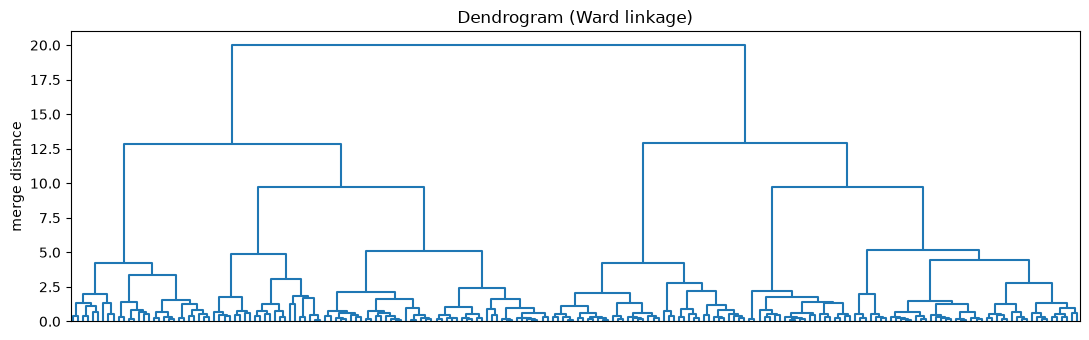

In [46]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

fig, ax = plt.subplots(figsize=(11, 3.5))
dendrogram(linkage(Z, method="ward"), ax=ax, no_labels=True, color_threshold=0)
ax.set_title("Dendrogram (Ward linkage)"); ax.set_ylabel("merge distance")
fig.tight_layout()

ward = AgglomerativeClustering(n_clusters=best_k, linkage="ward").fit_predict(Z)
print("agreement of K-Means and Ward partitions, adjusted Rand index:", round(adjusted_rand_score(km.labels_, ward), 3))

[extra] A clustering pipeline — `Pipeline([("scale", StandardScaler()), ("km", KMeans(...))])` — keeps the scaling with the model exactly as in the supervised case, which matters when new customers are to be assigned to existing segments.

## 9 Review

### Key concepts

| Area | Principle |
|---|---|
| Kinds of learning | Supervised: labels exist and are predicted. Unsupervised: no labels, structure is proposed. |
| CRISP-DM | Business question first; evaluation sends you back to preparation. |
| Leakage | Fit every learned step inside the pipeline, inside the training fold. |
| Metrics | Compare with a baseline; use precision–recall curves under imbalance; the confusion matrix contains the complete information. |
| Thresholds | Choose on out-of-fold training predictions with explicit costs; never on test labels. |
| Model selection | `best_score_` chose the winner; nested cross-validation estimates it. The test set is used once. |
| Clustering | Scale first; choose k with elbow and silhouette; evaluate by interpretation. |

### Review questions

1. You standardise features and run five-fold cross-validation. Where must the scaler be fitted for the score to be honest?
2. A dataset has 3 % positives and you can review a fixed number of flagged cases. Which curve tells you how well a model serves that budget, and why not the other?
3. Why is `best_score_` of `GridSearchCV` not an independent estimate of performance on new data?
4. A false negative costs ten times a false positive. Does the cost-minimising threshold move above or below 0.5?
5. 100 rows, 1,000 noise features, random labels, feature selection on all rows, cross-validated AUC 0.90. What happened, and what returns the AUC to 0.5?
6. Why can a high silhouette score accompany a partition that ignores most of the features?